# 3. 로지스틱 회귀 타이타닉 생존 예측 (Logistic Regression Titanic)

타이타닉 데이터셋(`data/titanic.csv` 캐시 우선, `sns.load_dataset('titanic')` fallback)에서 클래스 비율을 확인하고, 범주형 인코딩·훈련/테스트 분할 후 훈련 세트(`X_train`) 통계로만 결측 대체 및 스케일링(데이터 누수 방지)을 수행해 `LogisticRegression`으로 생존 여부를 예측하고 임계값(`threshold`) 조정 효과를 확인합니다.

원본 노트북 Lv2_Python_1120_logi_titanic.ipynb

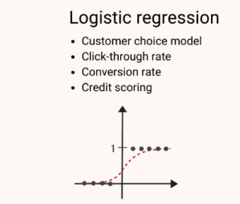

In [1]:
import seaborn as sns
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
from pathlib import Path
import pandas as pd
import seaborn as sns

# 로컬 titanic.csv 캐시 우선 로드, 없으면 seaborn 내장 데이터셋 fallback
data_dir = DATA_DIR if 'DATA_DIR' in globals() else Path('data')
if not (data_dir / 'titanic.csv').is_file():
    data_dir = Path('Study_Python') / '[8] Model_Evaluation' / 'data'
if not (data_dir / 'titanic.csv').is_file():
    data_dir = Path('..') / 'Study_Python' / '[8] Model_Evaluation' / 'data'

titanic_path = data_dir / 'titanic.csv'
if titanic_path.is_file():
    data = pd.read_csv(titanic_path)
else:
    data = sns.load_dataset('titanic')
data.head()

In [3]:
### survied 클래스 비율 확인
survived_counts = data['survived'].value_counts()
print(survived_counts)

survived
0    549
1    342
Name: count, dtype: int64


In [4]:
### survied 클래스 비율 확인- 백분률
survived_percentages = data['survived'].value_counts(normalize=True) * 100
print(survived_percentages)

# 0.6 : 0.4  성능지표 accuracy ?

########################
# 0.98 : 0.02  <--- 98%
########################
# 샘플링 5 : 5 학습데이터 비율
  ## 모델 성적표 ??? <--- 검증 SET ... 비율???


# 샘플링... 기준 7 : 3



survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


<Axes: xlabel='survived'>

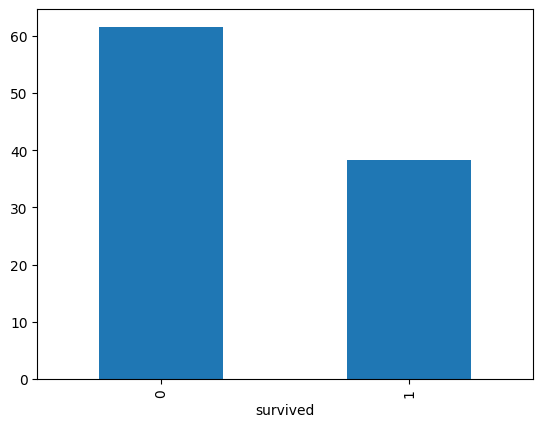

In [5]:
### 시각화
import matplotlib.pyplot as plt

barbolot = survived_percentages.plot(kind='bar')
barbolot

In [6]:
print(data.dtypes)

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object


In [7]:
# 데이터 전처리
# 'sex' 열을 숫자로 인코딩.
label_encoder = LabelEncoder()
data['sex'] = label_encoder.fit_transform(data['sex'].astype(str)) # .astype(str) : 'sex' 열을 문자열로 변환. object -> 문자열, 다시 숫자로 변환
# data['sex']
data.head()



,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,1,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,0,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,0,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,0,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,1,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [8]:
print(data.dtypes)

survived          int64
pclass            int64
sex               int64
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object


In [9]:
# 결측치 확인 (실제 결측 대체는 데이터 누수 방지를 위해 train_test_split 이후 X_train 중앙값으로만 수행)
print(data[['pclass', 'sex', 'age', 'fare']].isnull().sum())

In [10]:
# 사용할 특성 선택
   ############ 여러다른 특성 조합을 시도해 보세요.
# X = data[['pclass', 'sex', 'age']] # 전체 독립변수 수  12개
X = data[['pclass', 'sex', 'age', 'fare']] # 전체 독립변수 수  12개
y = data['survived']  # 정답, 종속변수

# SibSp: 타이타닉호에 탑승한 형제, 자매 또는 배우자의 수. 가족 구성원의 수가 생존 확률에 미치는 영향?
# Parch: 타이타닉호에 탑승한 부모 또는 자녀의 수. 이 역시 가족과 함께 여행하는 승객의 생존 확률에 미치는 영향?
# Fare: 탑승권 요금 -> 승객의 사회경제적 지위를 반영?
# Cabin: 객실 번호. 특정 객실이 위치한 선박의 구역이 생존에 영향? ex) 일구명보트에 더 가까운 객실
# Embarked: 승객이 타이타닉호에 탑승한 항구(C = Cherbourg, Q = Queenstown, S = Southampton) 생존율과의 관련?

y.head()

,survived
0,0
1,1
2,1
3,1
4,0


In [11]:
# 데이터를 훈련 세트와 테스트 세트로 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# 훈련 세트(X_train) 중앙값으로만 결측치 대체 (데이터 누수 방지)
train_medians = X_train.median(numeric_only=True)
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# 특성 스케일링 ... 여러 스케일러 확인, 이상치 확인
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_train

In [12]:
# 로지스틱 회귀 모델 생성 및 학습
model = LogisticRegression()
model.fit(X_train, y_train) ###  <--- 명확한 목적



LogisticRegression()

In [13]:
# 테스트 데이터에 대한 예측 수행
y_pred = model.predict(X_test)

In [14]:
# 모델 성능 평가        ### 다른 변수 조합에서의 결과 비교해 보기
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8044692737430168
Confusion Matrix:
 [[93 17]
 [18 51]]
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.85      0.84       110
           1       0.75      0.74      0.74        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



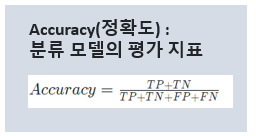

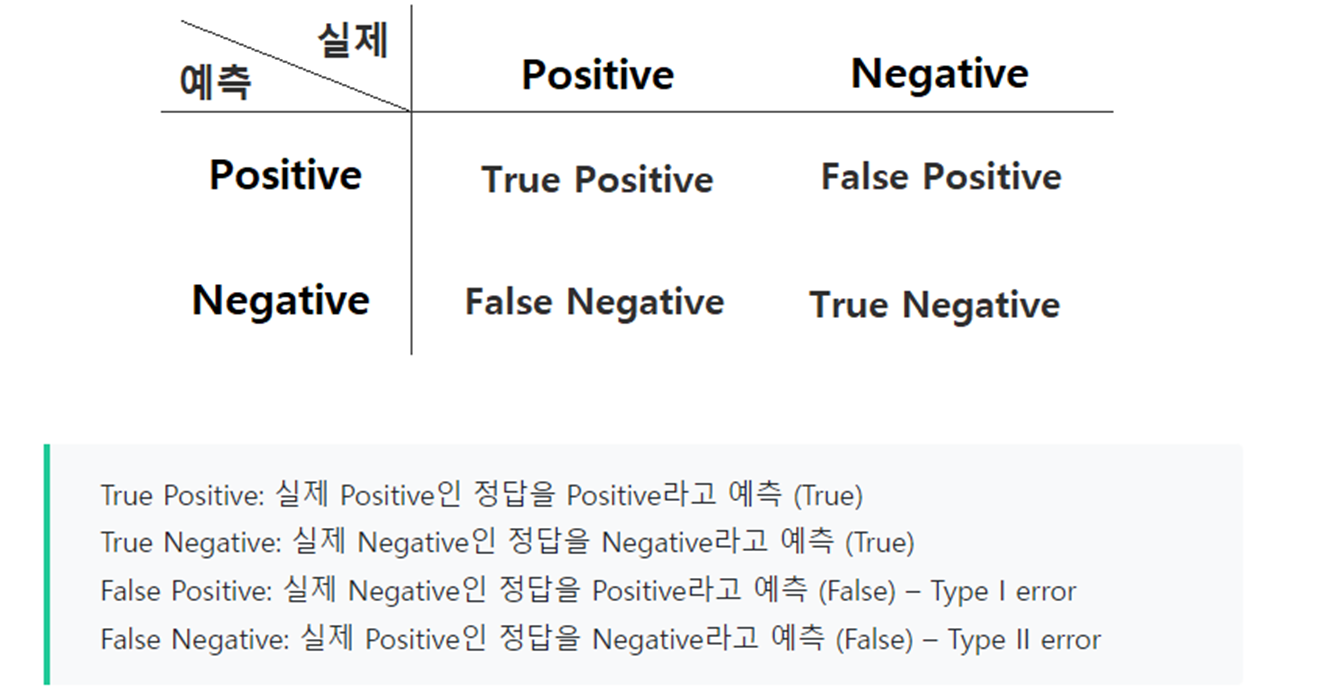

# (추가) 임계값 조정(0.5)?

In [15]:
# 각 클래스에 대한 확률 값 예측
y_prob = model.predict_proba(X_test)[:, 1]  # 클래스 1에 대한 확률만 추출
y_prob

array([0.09891011, 0.09864282, 0.18806079, 0.92631709, 0.57240715,
       0.48626191, 0.89200634, 0.91935785, 0.5192727 , 0.58016481,
       0.10510434, 0.72643775, 0.09865055, 0.89527596, 0.93369763,
       0.69366165, 0.11553676, 0.3081717 , 0.07878542, 0.22449897,
       0.31337236, 0.93963957, 0.09865007, 0.4863162 , 0.63090814,
       0.89120984, 0.08680648, 0.63069684, 0.81922439, 0.77713862,
       0.08407783, 0.65089719, 0.0987182 , 0.48680481, 0.09553331,
       0.45115951, 0.06055701, 0.24280055, 0.26298054, 0.11380004,
       0.23831037, 0.10844037, 0.09891173, 0.15383215, 0.90527474,
       0.09865619, 0.09865619, 0.94951866, 0.17885757, 0.2932341 ,
       0.48620763, 0.53384591, 0.90466402, 0.13068119, 0.48617505,
       0.27508309, 0.22177385, 0.71773196, 0.17236496, 0.0992512 ,
       0.1190975 , 0.57302714, 0.82993204, 0.48725001, 0.58913775,
       0.08680146, 0.85051857, 0.24460296, 0.91068036, 0.94257299,
       0.8243869 , 0.32066332, 0.49187362, 0.09866215, 0.11019

In [16]:

# 임계값을 0.7로 설정 (기본값은 0.5)
threshold = 0.7

# 임계값을 사용해 예측값 조정
y_pred = (y_prob >= threshold).astype(int)

print(y_pred)

[0 0 0 1 0 0 1 1 0 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 1 1 1 0 0 0
 0 1 0 0 0 0 0 0 1 0 0 1 1 0 1 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0
 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1
 1 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 0 1 0 0]
